# RQ3: Hallucination

Rebuilds the numbers behind Fig. 4 and the RQ3 text of the paper from the released result files in `results/` (tier A: no model, no GPU).
The hallucination rate eta is the share of *parseable* responses that contain at least one hallucinated SLO (see `RULEBOOK.md`). In the code the setups are called `zs3`, `fs3`, `zs3 CoT`, `fs3 CoT`; the paper writes `zs`, `fs`, `zs-cot`, `fs-cot`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
RES = Path("results")
pc = pd.read_csv(RES / "A-01_per_condition.csv")
eta = pc.set_index(["name", "prompt"])["all"].unstack("prompt")[["zs3", "fs3", "zs3 CoT", "fs3 CoT"]]
display(eta.round(3))

prompt,zs3,fs3,zs3 CoT,fs3 CoT
name,,,,
Gemma4-E2B,0.450,0.467,0.163,0.103
Gemma4-E4B,0.122,0.177,0.041,0.008
Granite-4.1-3B,0.602,0.355,0.414,0.204
Granite-4.1-8B,0.304,0.170,0.109,0.078
Llama-3.1-8B,0.477,0.398,0.437,0.347
Llama-3.2-3B,0.885,0.716,0.823,0.808
Ministral-3-3B,0.529,0.406,0.245,0.085
Ministral-3-8B,0.198,0.085,0.058,0.014
Qwen3.5-4B,0.131,0.110,0.018,0.013


## Fig. 4 (as printed in the paper)

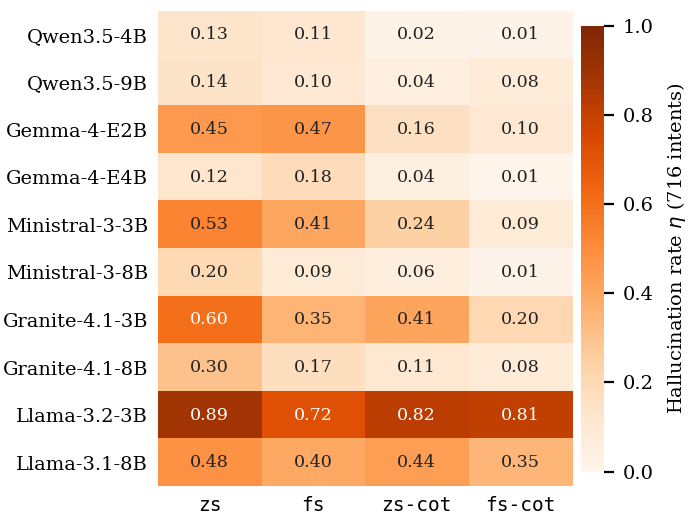

In [2]:
display(Image("figures/fig4_opt_i_heatmap.png", width=420))

## Checks against the sentences of Section IV-C
A failed assertion would mean the text and the data disagree.

In [3]:
allc = pd.read_csv(RES / "A-01_all_conditions.csv", index_col=0)["value"]
print(allc.round(4).to_dict())
assert (allc["all"], allc["valid"], allc["invalid"]) == (0.2706, 0.2686, 0.2762)
best = eta["fs3 CoT"].sort_values().head(2)
print("best configurations (fs-cot):", best.round(3).to_dict())
assert list(best.index) == ["Gemma4-E4B", "Qwen3.5-4B"] and round(best.iloc[0], 3) == 0.008 and round(best.iloc[1], 3) == 0.013

{'all': 0.2706, 'valid': 0.2686, 'invalid': 0.2762, 'constraint-level': 0.2334, 'error rate': 0.4491, 'unparseable': 0.0124}
best configurations (fs-cot): {'Gemma4-E4B': 0.008, 'Qwen3.5-4B': 0.013}


In [4]:
eff = pd.read_csv(RES / "A-04_setup_effects_pooled.csv", index_col="effect")
print(eff[["mean_diff", "models_lower"]])
assert eff.loc["reasoning (zs3 CoT - zs3)", "models_lower"] == 10      # reasoning lowers eta for all ten models with zero-shot prompts
assert eff.loc["reasoning on examples (fs3 CoT - fs3)", "models_lower"] == 9   # and for nine of ten with few-shot prompts
assert eff.loc["examples (fs3 - zs3)", "models_lower"] == 8            # examples alone lower it for eight
fam = pd.read_csv(RES / "A-01_per_family.csv", index_col="family")["all"]
print(fam.round(3).to_dict())
assert fam.round(3).to_dict() == {"Qwen": 0.080, "Gemma": 0.191, "Ministral": 0.203, "Granite": 0.279, "Llama": 0.610}

                                           mean_diff  models_lower
effect                                                            
examples (fs3 - zs3)                         -0.0854             8
reasoning (zs3 CoT - zs3)                    -0.1489            10
both (fs3 CoT - zs3)                         -0.2106            10
reasoning on examples (fs3 CoT - fs3)        -0.1253             9
examples on reasoning (fs3 CoT - zs3 CoT)    -0.0618             9
{'Qwen': 0.08, 'Gemma': 0.191, 'Ministral': 0.203, 'Granite': 0.279, 'Llama': 0.61}


In [5]:
size = pd.read_csv(RES / "A-04_size_per_family.csv")
size = size[size.scope == "all"].set_index("family")["diff_large_minus_small"]
print(size.round(3).to_dict())
assert (size < 0).sum() == 4 and size["Qwen"] > 0          # the larger model hallucinates less in four of five families; Qwen is the exception
pm = pd.read_csv(RES / "A-01_per_model.csv", index_col=0)["all"]
print("Qwen3.5-9B vs 4B:", round(pm["Qwen3.5-9B"], 3), "vs", round(pm["Qwen3.5-4B"], 3))
assert round(pm["Qwen3.5-9B"], 3) == 0.093 and round(pm["Qwen3.5-4B"], 3) == 0.068

{'Qwen': 0.024, 'Gemma': -0.209, 'Ministral': -0.229, 'Granite': -0.228, 'Llama': -0.393}
Qwen3.5-9B vs 4B: 0.093 vs 0.068


In [6]:
kind = pd.read_csv(RES / "A-05_kind.csv")
v = kind[kind.validity == "valid"].set_index("name")
n_value = int((v["Value"] > v["Requirement"]).sum())
print("valid intents: models with more unsupported values than unsupported requirements:", n_value, "of", len(v))
assert n_value == 8

valid intents: models with more unsupported values than unsupported requirements: 8 of 10


Table III of the paper (`results/tab3_rq3.tex`) shows two examples from the label files (records 215 and 98); the label files themselves are released with the camera-ready archive.